# PathSnap Model Evaluation & Metrics

This notebook evaluates the exported Bayesian-tuned Random Forest on the reserved student-test partition and evaluates its HMM/Viterbi route reconstruction. It uses saved project data and computes actual metrics; it contains no sample predictions or placeholder values.

Run the cleaning/feature-engineering notebook and `02_Bayesian_Optimization_and_HMM_Route_Reconstruction.ipynb` first. The student-test partition is used only for this final report, not fitting or model selection.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)

working_directory = Path.cwd().resolve()
project_root = next(
    (
        candidate
        for candidate in [working_directory, *working_directory.parents]
        if (candidate / 'src' / 'models' / 'bayesian_hmm.py').is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate the PathSnap project root.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.artifact_inference import load_model, predict_candidate_probabilities
from src.models.bayesian_hmm import evaluate_hmm_partition

print(f'Project root: {project_root}')

Project root: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap


In [2]:
artifact_root = project_root / 'artifacts' / 'map_matching_models'
feature_root = project_root / 'data' / 'processed' / 'features'
cleaned_root = project_root / 'data' / 'processed' / 'cleaned'
bayesian_results = project_root / 'results' / 'candidate_models' / 'bayesian_hmm'
output_root = project_root / 'results' / 'comprehensive_evaluation'
output_root.mkdir(parents=True, exist_ok=True)

manifest = json.loads((artifact_root / 'manifest.json').read_text(encoding='utf-8'))
feature_schema = json.loads((artifact_root / 'feature_schema.json').read_text(encoding='utf-8'))
model_path = artifact_root / manifest['recommended_model']
model_bundle = load_model(model_path)
feature_columns = feature_schema['feature_columns']
if model_bundle['feature_columns'] != feature_columns:
    raise ValueError('The selected model feature order does not match feature_schema.json.')
if model_bundle.get('student_test_used_for_training', False):
    raise ValueError('The selected model manifest indicates student-test leakage.')

bayesian_summary = json.loads(
    (bayesian_results / 'bayesian_optimization_summary.json').read_text(encoding='utf-8')
)
refit_summary = json.loads(
    (bayesian_results / 'bayesian_refit_summary.json').read_text(encoding='utf-8')
)
if refit_summary.get('student_test_used_for_training', True):
    raise ValueError('The tuned model refit record indicates student-test leakage.')

audit = pd.read_csv(feature_root / 'feature_quality_audit.csv', dtype={'trip_id': str})
student_test_trip_ids = sorted(
    audit.loc[audit['partition'] == 'student_test', 'trip_id'].unique().tolist()
)
if not student_test_trip_ids:
    raise ValueError('No student-test trips are listed in the feature-quality audit.')

print(f"Recommended model: {model_bundle['model_name']}")
print(f"Validation selection metric: {bayesian_summary['selection_metric']}")
print(f"Best validation Top-1: {bayesian_summary['best_validation_top1_accuracy']:.4f}")
print(f'Student-test trips: {len(student_test_trip_ids)}')
print(f"Refit training time: {refit_summary['training_seconds']:.2f} seconds")

Recommended model: Random Forest (Bayesian tuned)
Validation selection metric: observation_top1_accuracy
Best validation Top-1: 0.9000
Student-test trips: 10
Refit training time: 111.38 seconds


## Metric definitions

- **Candidate-row classification** is binary: does each generated candidate match the reference arc? Accuracy, macro precision/recall/F1, confusion matrix, and binary log loss are computed only for `supervision_usable` candidate rows. This avoids treating quarantined labels as ground truth.
- **Observation-level Top-1** selects the candidate with the highest model probability per usable GPS observation.
- **Candidate miss rate** counts reliable reference observations whose correct arc is absent from the generated candidate set. It is measured separately because missed references cannot appear in the candidate-row classifier metrics.
- **Route and sequence metrics** come from a fresh HMM/Viterbi evaluation of the same student-test trips. Training and model selection remain confined to training/validation data.

In [3]:
def parse_boolean_column(values):
    if pd.api.types.is_bool_dtype(values.dtype):
        return values.fillna(False).astype(bool)
    parsed = values.astype('string').str.strip().str.lower().map(
        {'true': True, 'false': False, '1': True, '0': False}
    )
    if parsed.isna().any():
        raise ValueError('A boolean candidate column contains an unknown value.')
    return parsed.astype(bool)


boolean_columns = [
    'supervision_usable',
    'is_target',
    'label_confident',
    'label_unambiguous',
    'candidate_label_found',
    'route_geometry_suspect',
    'route_sequence_suspect',
    'route_sequence_consistent',
]
required_columns = feature_columns + [
    'observation_id',
    'candidate_arc_id',
    'candidate_rank',
    *boolean_columns,
]

candidate_true_parts = []
candidate_probability_parts = []
top1_reference_arcs = []
top1_predicted_arcs = []
candidate_miss_count = 0
reliable_reference_count = 0
candidate_row_count = 0
model_inference_seconds = 0.0

for trip_id in student_test_trip_ids:
    candidate_path = feature_root / 'student_test' / trip_id / 'candidates.csv.gz'
    if not candidate_path.is_file():
        raise FileNotFoundError(f'Missing student-test candidates: {candidate_path}')
    frame = pd.read_csv(candidate_path, usecols=required_columns)
    if frame.empty:
        raise ValueError(f'No candidate rows for student-test trip {trip_id}.')
    for column in boolean_columns:
        frame[column] = parse_boolean_column(frame[column])
    if not np.isfinite(frame[feature_columns].to_numpy(dtype=float)).all():
        raise ValueError(f'Non-finite model features found in trip {trip_id}.')

    start_time = time.perf_counter()
    probabilities = predict_candidate_probabilities(model_bundle, frame)
    model_inference_seconds += time.perf_counter() - start_time
    candidate_row_count += len(frame)
    frame['candidate_probability'] = probabilities
    frame['trip_id'] = trip_id

    observation_metadata = frame.drop_duplicates('observation_id')
    reliable = (
        observation_metadata['label_confident']
        & observation_metadata['label_unambiguous']
        & observation_metadata['route_sequence_consistent']
        & ~observation_metadata['route_geometry_suspect']
        & ~observation_metadata['route_sequence_suspect']
    )
    reliable_metadata = observation_metadata.loc[reliable]
    reliable_reference_count += len(reliable_metadata)
    candidate_miss_count += int((~reliable_metadata['candidate_label_found']).sum())

    usable = frame.loc[frame['supervision_usable']].copy()
    if usable.empty:
        continue
    targets_per_observation = usable.groupby('observation_id')['is_target'].sum()
    if not (targets_per_observation == 1).all():
        raise ValueError(f'Expected exactly one usable target candidate in {trip_id}.')
    candidate_true_parts.append(usable['is_target'].to_numpy(dtype=np.uint8))
    candidate_probability_parts.append(
        usable['candidate_probability'].to_numpy(dtype=float)
    )

    best_candidates = (
        usable.sort_values(
            ['observation_id', 'candidate_probability', 'candidate_rank'],
            ascending=[True, False, True],
            kind='stable',
        )
        .drop_duplicates('observation_id')
        .set_index('observation_id')['candidate_arc_id']
    )
    reference_candidates = usable.loc[usable['is_target']].set_index(
        'observation_id'
    )['candidate_arc_id']
    if not best_candidates.index.equals(reference_candidates.index):
        reference_candidates = reference_candidates.reindex(best_candidates.index)
    top1_reference_arcs.extend(reference_candidates.to_numpy(dtype=int))
    top1_predicted_arcs.extend(best_candidates.to_numpy(dtype=int))

if not candidate_true_parts or not top1_reference_arcs:
    raise ValueError('No reliable student-test candidate labels were available.')
if reliable_reference_count == 0:
    raise ValueError('Candidate miss rate has no reliable reference observations.')

candidate_y_true = np.concatenate(candidate_true_parts)
candidate_y_probability = np.clip(
    np.concatenate(candidate_probability_parts), 1e-7, 1 - 1e-7
)
threshold = float(model_bundle.get('classification_threshold', 0.5))
candidate_y_pred = (candidate_y_probability >= threshold).astype(np.uint8)
candidate_confusion = confusion_matrix(candidate_y_true, candidate_y_pred, labels=[0, 1])
top1_observation_accuracy = accuracy_score(
    top1_reference_arcs, top1_predicted_arcs
)

print(f'Evaluated {candidate_row_count:,} candidate rows across {len(student_test_trip_ids)} trips.')
print(f'Usable candidate rows: {len(candidate_y_true):,}')
print(f'Reliable references: {reliable_reference_count:,}; candidate misses: {candidate_miss_count:,}')
print(f'Model scoring time: {model_inference_seconds:.3f} seconds')

Evaluated 553,240 candidate rows across 10 trips.
Usable candidate rows: 278,670
Reliable references: 10,496; candidate misses: 0
Model scoring time: 1.213 seconds


In [4]:
hmm_predictions, route_sequences, hmm_metrics = evaluate_hmm_partition(
    feature_root=feature_root,
    cleaned_root=cleaned_root,
    model_bundle=model_bundle,
    output_root=output_root,
    partition='student_test',
)

if not np.isclose(
    top1_observation_accuracy,
    hmm_metrics['top1_observation_accuracy'],
    atol=1e-12,
):
    raise AssertionError('Candidate Top-1 accuracy does not match the HMM evaluator.')

print(f"HMM/Viterbi evaluated {hmm_metrics['scored_trip_count']} scorable trips.")
print(f"Observation-level Viterbi accuracy: {hmm_metrics['viterbi_observation_accuracy']:.4f}")
print(f"Viterbi route continuity: {hmm_metrics['viterbi_route_continuity']:.4f}")

HMM/Viterbi evaluated 9 scorable trips.
Observation-level Viterbi accuracy: 0.9454
Viterbi route continuity: 0.9672


## Final performance summary

Candidate precision/recall/F1 below are reported both as macro averages and for the positive (correct-road) class. The confusion matrix order is `[[TN, FP], [FN, TP]]`. Timing values are measured or read from the actual tuned-model refit record; they are not defaults.

In [5]:
candidate_classification = {
    'candidate_accuracy': accuracy_score(candidate_y_true, candidate_y_pred),
    'candidate_precision_macro': precision_score(
        candidate_y_true, candidate_y_pred, average='macro', zero_division=0
    ),
    'candidate_recall_macro': recall_score(
        candidate_y_true, candidate_y_pred, average='macro', zero_division=0
    ),
    'candidate_f1_macro': f1_score(
        candidate_y_true, candidate_y_pred, average='macro', zero_division=0
    ),
    'candidate_target_precision': precision_score(
        candidate_y_true, candidate_y_pred, pos_label=1, zero_division=0
    ),
    'candidate_target_recall': recall_score(
        candidate_y_true, candidate_y_pred, pos_label=1, zero_division=0
    ),
    'candidate_target_f1': f1_score(
        candidate_y_true, candidate_y_pred, pos_label=1, zero_division=0
    ),
    'candidate_log_loss': log_loss(
        candidate_y_true, candidate_y_probability, labels=[0, 1]
    ),
}

summary = {
    'model': model_bundle['model_name'],
    'evaluation_partition': 'student_test',
    'test_trip_count': len(student_test_trip_ids),
    'scored_trip_count': int(hmm_metrics['scored_trip_count']),
    'candidate_rows_total': int(candidate_row_count),
    'candidate_rows_evaluated': int(len(candidate_y_true)),
    **candidate_classification,
    'candidate_confusion_matrix_tn_fp_fn_tp': candidate_confusion.ravel().tolist(),
    'candidate_miss_count': int(candidate_miss_count),
    'reliable_reference_observations': int(reliable_reference_count),
    'candidate_miss_rate': candidate_miss_count / reliable_reference_count,
    'observation_top1_accuracy': float(top1_observation_accuracy),
    'viterbi_observation_accuracy': float(hmm_metrics['viterbi_observation_accuracy']),
    'top1_route_continuity': float(hmm_metrics['top1_route_continuity']),
    'viterbi_route_continuity': float(hmm_metrics['viterbi_route_continuity']),
    'expanded_route_continuity': float(hmm_metrics['expanded_route_continuity']),
    'viterbi_transition_feasibility': float(hmm_metrics['viterbi_transition_feasibility']),
    'top1_sequence_order_consistency': float(hmm_metrics['top1_sequence_order_consistency']),
    'viterbi_sequence_order_consistency': float(hmm_metrics['viterbi_sequence_order_consistency']),
    'top1_exact_trip_rate': float(hmm_metrics['top1_exact_trip_rate']),
    'viterbi_exact_trip_rate': float(hmm_metrics['viterbi_exact_trip_rate']),
    'training_time_seconds': float(refit_summary['training_seconds']),
    'candidate_model_inference_seconds': float(model_inference_seconds),
    'candidate_model_inference_ms_per_trip': float(
        model_inference_seconds / len(student_test_trip_ids) * 1000
    ),
    'hmm_model_inference_seconds': float(hmm_metrics['inference_seconds']),
    'viterbi_decode_seconds': float(hmm_metrics['viterbi_seconds']),
    'student_test_used_for_training_or_selection': False,
}

summary_path = output_root / 'comprehensive_evaluation_summary.csv'
pd.DataFrame([summary]).to_csv(summary_path, index=False)
confusion_path = output_root / 'candidate_confusion_matrix.csv'
pd.DataFrame(
    candidate_confusion,
    index=['true_not_target', 'true_target'],
    columns=['predicted_not_target', 'predicted_target'],
).to_csv(confusion_path)
classification_path = output_root / 'candidate_classification_report.csv'
pd.DataFrame(
    classification_report(
        candidate_y_true,
        candidate_y_pred,
        labels=[0, 1],
        target_names=['not_target', 'target'],
        output_dict=True,
        zero_division=0,
    )
).T.to_csv(classification_path, index_label='class')

summary_json = {
    key: (None if isinstance(value, float) and not np.isfinite(value) else value)
    for key, value in summary.items()
}
(output_root / 'comprehensive_evaluation_summary.json').write_text(
    json.dumps(summary_json, indent=2, allow_nan=False), encoding='utf-8'
)

display(pd.DataFrame([summary]).T.rename(columns={0: 'student_test'}))
print(f'Saved summary: {summary_path}')
print(f'Saved candidate confusion matrix: {confusion_path}')
print(f'Saved classification report: {classification_path}')
print(f'Saved HMM predictions and route sequence under: {output_root}')

,student_test
model,Random Forest (Bayesian tuned)
evaluation_partition,student_test
test_trip_count,10
scored_trip_count,9
candidate_rows_total,553240
candidate_rows_evaluated,278670
candidate_accuracy,0.990695
candidate_precision_macro,0.942376
candidate_recall_macro,0.92733
candidate_f1_macro,0.934712


Saved summary: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\comprehensive_evaluation\comprehensive_evaluation_summary.csv
Saved candidate confusion matrix: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\comprehensive_evaluation\candidate_confusion_matrix.csv
Saved classification report: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\comprehensive_evaluation\candidate_classification_report.csv
Saved HMM predictions and route sequence under: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\comprehensive_evaluation


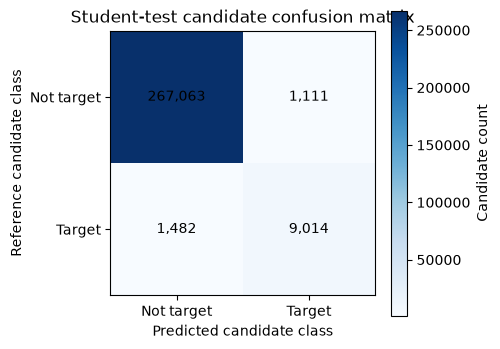

Primary model-selection metric: observation-level Top-1 accuracy on the validation split (0.9000). It measures whether the highest-scored candidate matches the reference road arc for each GPS observation, and student-test data was not used to choose the model.


In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(candidate_confusion, cmap='Blues')
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=['Not target', 'Target'],
    yticklabels=['Not target', 'Target'],
    xlabel='Predicted candidate class',
    ylabel='Reference candidate class',
    title='Student-test candidate confusion matrix',
)
for row in range(2):
    for column in range(2):
        ax.text(column, row, f'{candidate_confusion[row, column]:,}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Candidate count')
fig.tight_layout()
plt.show()

print(
    'Primary model-selection metric: observation-level Top-1 accuracy on the '
    f'validation split ({bayesian_summary["best_validation_top1_accuracy"]:.4f}). '
    'It measures whether the highest-scored candidate matches the reference '
    'road arc for each GPS observation, and student-test data was not used '
    'to choose the model.'
)

## Interpretation notes

Candidate-row accuracy can be high because non-target candidates outnumber target candidates; interpret it alongside macro/target precision, recall, F1, log loss, and observation-level Top-1. Route continuity and sequence-level results are calculated from the actual Viterbi output, not constants. Training time is the recorded final refit time; inference time is measured during this notebook run and can vary by machine.

Generated files are in `results/comprehensive_evaluation/`: the summary CSV/JSON, candidate confusion matrix and classification report, HMM predictions, Viterbi route sequence, and HMM metrics.